## 2107540 Data Science for Environmental and Sustainability
## Lecture 10 : Intro to Machine Learning I
### Done by : 6730084521 Chatrphol Ovanonchai

## Step 1: Import the dataset

In [40]:
import pandas as pd
import numpy as np
# Load datasets
info = pd.read_csv("Measurement_info.csv.gz")
summary = pd.read_csv("Measurement_summary.csv.gz")

In [41]:
# Create binary sensor status
status_df = (
 info.groupby(["Measurement date", "Station code"])
 ["Instrument status"]
 .apply(lambda x: (x != 0).any())
 .reset_index(name="Sensor_Status")
)

# Convert target to integer
status_df["Sensor_Status"] = (
 status_df["Sensor_Status"].astype(int)
)

In [42]:
df = summary.merge( right = status_df , on = ["Measurement date" , "Station code"] , how = "inner" , validate = None)
print(df.shape)
print(df["Sensor_Status"].value_counts())

(647511, 12)
Sensor_Status
0    605051
1     42460
Name: count, dtype: int64


## Step 2: Define feature and target

In [43]:
## define feature & targets
features = [
 "SO2", "NO2", "O3",
 "CO", "PM10", "PM2.5"
]
X = df[features]
y = df["Sensor_Status"]

## Step 3: Train/test Split

In [44]:
## convert to datetime
df["Measurement date"] = pd.to_datetime(
 df["Measurement date"]
)
df = df.sort_values("Measurement date") # sort by measurement date
split_index = int(len(df) * 0.8)

## define train & test dataset 
train_df = df.iloc[:split_index]
test_df = df.iloc[split_index:]

## define X_train , X_test , y_train , y_test 
X_train = train_df[features]
X_test = test_df[features]
y_train = train_df["Sensor_Status"]
y_test = test_df["Sensor_Status"]

In [45]:
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nClass distribution in training set:")
print(y_train.value_counts(normalize=True))
print("\nClass distribution in testing set:")
print(y_test.value_counts(normalize=True))

Training set: (518008, 6)
Testing set: (129503, 6)

Class distribution in training set:
Sensor_Status
0    0.940615
1    0.059385
Name: proportion, dtype: float64

Class distribution in testing set:
Sensor_Status
0    0.90967
1    0.09033
Name: proportion, dtype: float64


## Step 4: Feature Scaling

In [46]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Step 5: Build the Models

In [47]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
models = {
 "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
 "Naive Bayes": GaussianNB(),
 "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42), # 1000 loop 
 "SVM": LinearSVC(class_weight="balanced", max_iter=2000, random_state=42), # 2000 loop
 "KNN": KNeighborsClassifier(n_neighbors=5)
}

## Step 6: Fit the Models and Make Predictions

In [48]:
predictions = {}
for name, model in models.items():
    print(f"Training {name}...")
    # Select scaled or original data
    if name in ["Logistic Regression", "SVM", "KNN"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    
    ## add to dict
    predictions[name] = y_pred
    
print("All models have been trained.")

Training Decision Tree...
Training Naive Bayes...
Training Logistic Regression...
Training SVM...
Training KNN...
All models have been trained.


## Step 7: Classification Report

In [49]:
from sklearn.metrics import classification_report
for name, y_pred in predictions.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    
    print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Non-normal"],
    zero_division=0
    ))

Decision Tree
              precision    recall  f1-score   support

      Normal       0.97      0.97      0.97    117805
  Non-normal       0.69      0.67      0.68     11698

    accuracy                           0.94    129503
   macro avg       0.83      0.82      0.82    129503
weighted avg       0.94      0.94      0.94    129503

Naive Bayes
              precision    recall  f1-score   support

      Normal       0.94      1.00      0.97    117805
  Non-normal       0.94      0.32      0.48     11698

    accuracy                           0.94    129503
   macro avg       0.94      0.66      0.72    129503
weighted avg       0.94      0.94      0.92    129503

Logistic Regression
              precision    recall  f1-score   support

      Normal       0.93      0.95      0.94    117805
  Non-normal       0.40      0.32      0.36     11698

    accuracy                           0.90    129503
   macro avg       0.67      0.64      0.65    129503
weighted avg       0.89     

## Step 8: Confusion Matrix

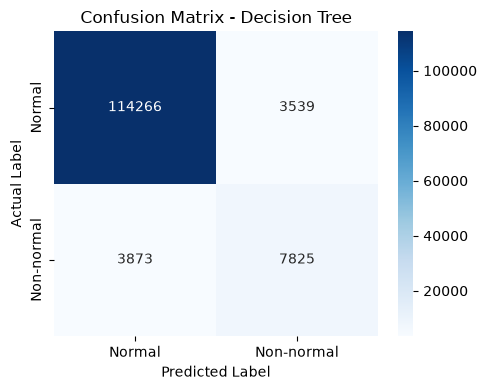

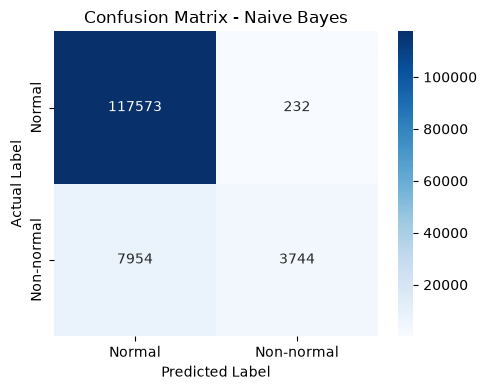

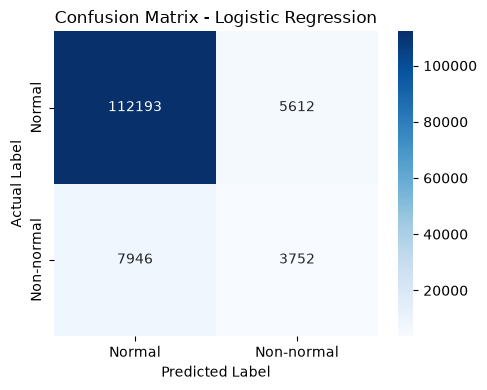

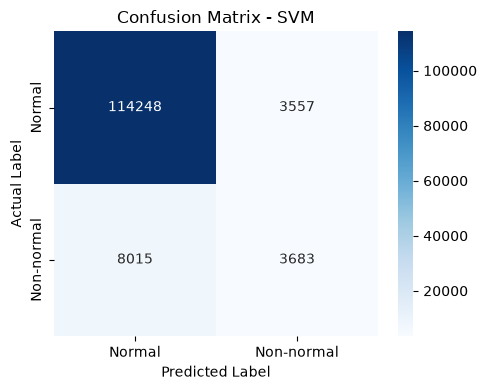

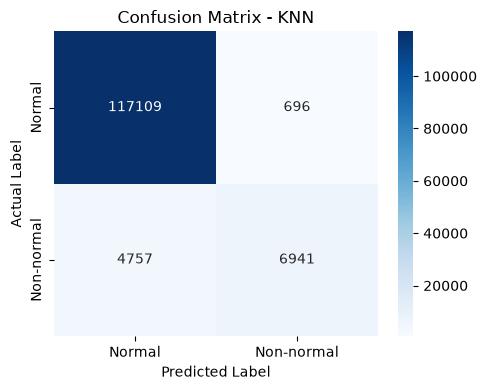

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Non-normal"],
    yticklabels=["Normal", "Non-normal"]
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

## Step 9: Model Comparison

In [51]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
results = []
for name, y_pred in predictions.items():
    results.append({
    "Model": name,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
    y_test, y_pred, zero_division=0
    ),
    "Recall": recall_score(
    y_test, y_pred, zero_division=0
    ),
    "F1-score": f1_score(
    y_test, y_pred, zero_division=0
    )
    })
    
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
 by="F1-score",
 ascending=False
)
print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1-score
4                  KNN    0.9579     0.9089  0.5933    0.7180
0        Decision Tree    0.9428     0.6886  0.6689    0.6786
1          Naive Bayes    0.9368     0.9416  0.3201    0.4777
3                  SVM    0.9106     0.5087  0.3148    0.3890
2  Logistic Regression    0.8953     0.4007  0.3207    0.3563


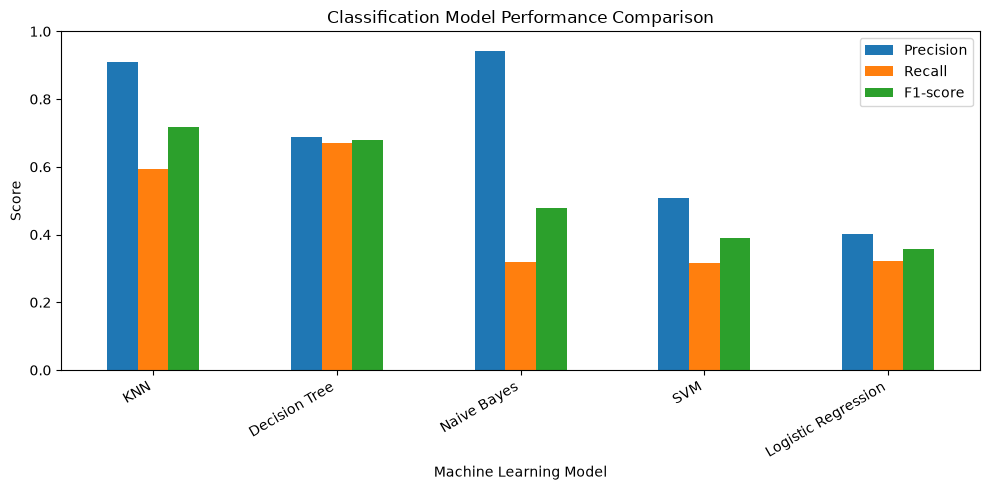

In [52]:
metrics = ["Precision", "Recall", "F1-score"]
results_plot = results_df.set_index("Model")[metrics]
results_plot.plot(
 kind="bar",
 figsize=(10, 5)
)
plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()